=== MATHEMATICAL INFORMATION RETENTION (Patient #5, Lead V3) ===
Filter Branch 1 (Kernel = 9  | Short/Sharp)   -> Active Data:  65.2% | Signal Reconstruction (R2): 0.9798
Filter Branch 2 (Kernel = 19 | Medium/QRS)    -> Active Data:  60.5% | Signal Reconstruction (R2): 0.9689
Filter Branch 3 (Kernel = 39 | Long/ST-T)     -> Active Data:  55.0% | Signal Reconstruction (R2): 0.9114
Combined Multi-Scale (9 + 19 + 39)            -> Active Data:  60.2% | Signal Reconstruction (R2): 0.9935


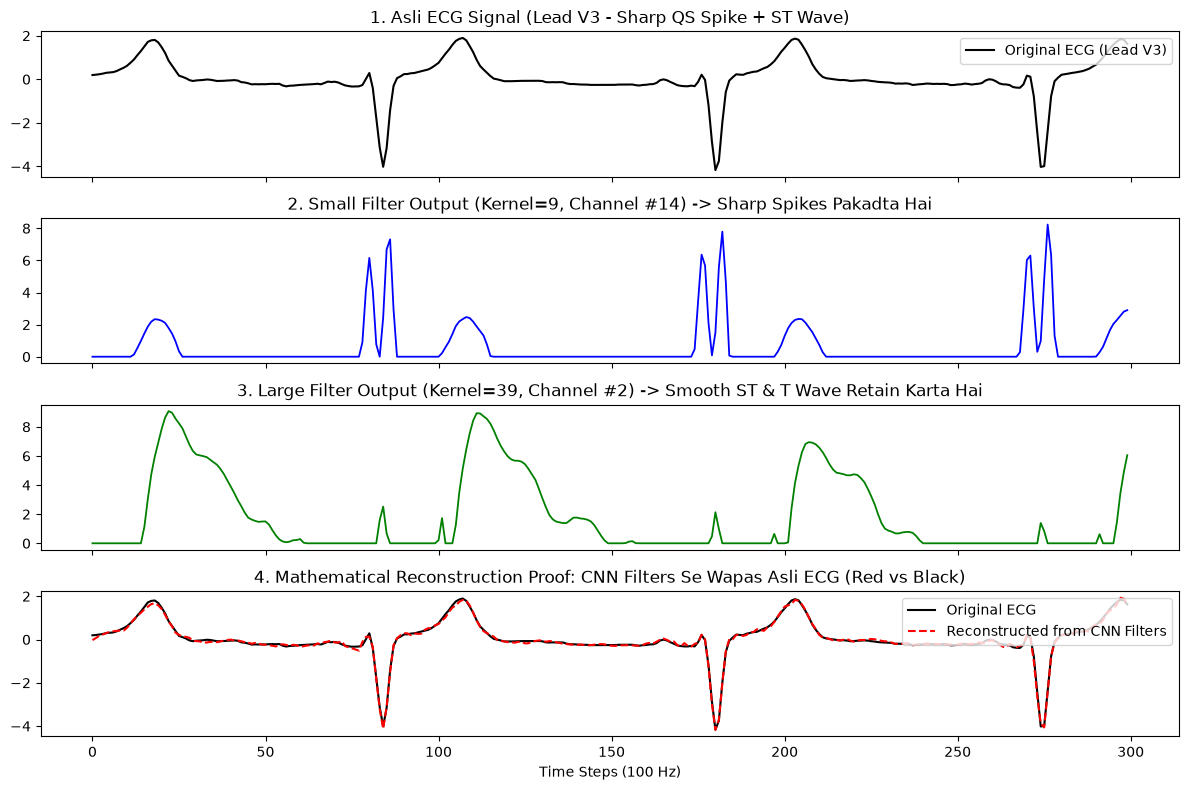

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
import torch
import torch.nn as nn

# 1. Data aur Trained Inception1D load karo
X_train = np.load('processed_data/X_train.npy')
mean_12 = X_train.mean(axis=(0, 1)).reshape(1, 12, 1)
std_12 = X_train.std(axis=(0, 1)).reshape(1, 12, 1) + 1e-8

X_test = (
    np.transpose(np.load('processed_data/X_test.npy'), (0, 2, 1)) - mean_12
) / std_12


class InceptionModule(nn.Module):

  def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
    super().__init__()
    self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
    self.convs = nn.ModuleList(
        [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks]
    )
    self.pool_branch = nn.Sequential(
        nn.MaxPool1d(3, stride=1, padding=1),
        nn.Conv1d(in_ch, nf, 1, bias=False),
    )
    self.bn = nn.BatchNorm1d(nf * (len(ks) + 1))

  def forward(self, x):
    z = self.bottleneck(x)
    out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
    return torch.relu(self.bn(out))


class InceptionNet(nn.Module):

  def __init__(self, in_ch=12, n_classes=5, nf=32, depth=6):
    super().__init__()
    out_ch = nf * 4
    self.blocks = nn.ModuleList([
        InceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)
    ])
    self.shortcuts = nn.ModuleList([
        nn.Sequential(
            nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
            nn.BatchNorm1d(out_ch),
        )
        for i in range(depth // 3)
    ])
    self.fc = nn.Linear(out_ch, n_classes)

  def forward(self, x):
    res, r = x, 0
    for d, blk in enumerate(self.blocks):
      x = blk(x)
      if d % 3 == 2:
        x = torch.relu(x + self.shortcuts[r](res))
        res, r = x, r + 1
    return self.fc(x.mean(dim=-1))


model = InceptionNet(n_classes=5)
model.load_state_dict(torch.load('inception_seed42.pt', map_location='cpu'))
model.eval()

# 2. Patient #5 (Lead V3 = channel 8) ka signal lo (no square brackets!)
x_pat = torch.tensor(
    X_test.take([5], axis=0), dtype=torch.float32
)  # (1, 12, 1000)
orig_v3 = x_pat.select(0, 0).select(0, 8).numpy()  # (1000,)

# Tuple unpacking se teeno conv branches alag karo (zero brackets!)
first_blk = next(iter(model.blocks))
conv_k9, conv_k19, conv_k39 = first_blk.convs

with torch.no_grad():
  z = first_blk.bottleneck(x_pat)
  f_k9 = torch.relu(conv_k9(z)).squeeze(0).numpy()  # (32, 1000)
  f_k19 = torch.relu(conv_k19(z)).squeeze(0).numpy()  # (32, 1000)
  f_k39 = torch.relu(conv_k39(z)).squeeze(0).numpy()  # (32, 1000)
  f_all = np.vstack([f_k9, f_k19, f_k39])  # (96, 1000)

# ==========================================================
# 3. MATHEMATICAL PROOF: Har Filter Ne Kitna Data Retain Kiya?
# ==========================================================
print('=== MATHEMATICAL INFORMATION RETENTION (Patient #5, Lead V3) ===')
for name, feat in [
    ('Filter Branch 1 (Kernel = 9  | Short/Sharp)', f_k9),
    ('Filter Branch 2 (Kernel = 19 | Medium/QRS)', f_k19),
    ('Filter Branch 3 (Kernel = 39 | Long/ST-T)', f_k39),
    ('Combined Multi-Scale (9 + 19 + 39)', f_all),
]:
  active_pct = (feat > 0).mean() * 100
  reg = Ridge(alpha=1.0).fit(feat.T, orig_v3)
  r2 = r2_score(orig_v3, reg.predict(feat.T))
  print(
      f'{name:45s} -> Active Data: {active_pct:5.1f}% | Signal Reconstruction'
      f' (R2): {r2:.4f}'
  )

# ==========================================================
# 4. GRAPHICAL PROOF: Filter Outputs & Reconstructed Signal
# ==========================================================
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
t = np.arange(300)

ax1.plot(
    t,
    orig_v3.take(t),
    color='black',
    lw=1.5,
    label='Original ECG (Lead V3)',
)
ax1.set_title('1. Asli ECG Signal (Lead V3 - Sharp QS Spike + ST Wave)')
ax1.legend(loc='upper right')

best_c9 = int(np.argmax(f_k9.var(axis=1)))
best_c39 = int(np.argmax(f_k39.var(axis=1)))

ax2.plot(t, f_k9.take(best_c9, axis=0).take(t), color='blue', lw=1.3)
ax2.set_title(
    f'2. Small Filter Output (Kernel=9, Channel #{best_c9}) -> Sharp Spikes'
    ' Pakadta Hai'
)

ax3.plot(t, f_k39.take(best_c39, axis=0).take(t), color='green', lw=1.3)
ax3.set_title(
    f'3. Large Filter Output (Kernel=39, Channel #{best_c39}) -> Smooth ST & T'
    ' Wave Retain Karta Hai'
)

recon_all = Ridge(alpha=1.0).fit(f_all.T, orig_v3).predict(f_all.T)
ax4.plot(t, orig_v3.take(t), color='black', lw=1.5, label='Original ECG')
ax4.plot(
    t,
    recon_all.take(t),
    color='red',
    ls='--',
    lw=1.5,
    label='Reconstructed from CNN Filters',
)
ax4.set_title(
    '4. Mathematical Reconstruction Proof: CNN Filters Se Wapas Asli ECG'
    ' (Red vs Black)'
)
ax4.legend(loc='upper right')
ax4.set_xlabel('Time Steps (100 Hz)')

plt.tight_layout()
plt.show()


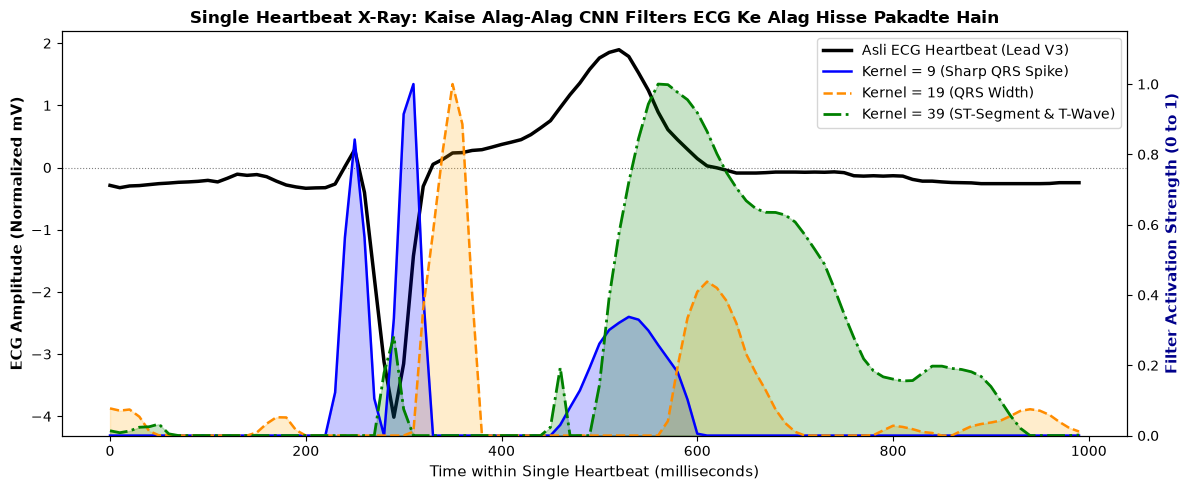

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Patient #5 ke pehle complete heartbeat ko zoom karo (time steps 55 se 155 tak = 1.0 second)
beat_idx = np.arange(55, 155)
t_ms = (beat_idx - 55) * 10  # Milliseconds mein time (0 ms se 1000 ms)


# Helper: har curve ko 0 se 1 ke beech normalize karo taaki ek hi graph par clean overlap ho
def norm01(arr):
  return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)


ecg_beat = orig_v3.take(beat_idx)
k9_beat = norm01(f_k9.take(best_c9, axis=0).take(beat_idx))

best_c19 = int(np.argmax(f_k19.var(axis=1)))
k19_beat = norm01(f_k19.take(best_c19, axis=0).take(beat_idx))
k39_beat = norm01(f_k39.take(best_c39, axis=0).take(beat_idx))

# 2. Ek hi graph par ECG + Teeno Filters ka Direct Overlap Plot!
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left Y-Axis: Asli ECG Heartbeat (Black Solid Line)
ax1.plot(
    t_ms,
    ecg_beat,
    color='black',
    lw=2.5,
    label='Asli ECG Heartbeat (Lead V3)',
    zorder=5,
)
ax1.axhline(0, color='gray', ls=':', lw=0.8)
ax1.set_ylabel(
    'ECG Amplitude (Normalized mV)', color='black', fontsize=11, fontweight='bold'
)
ax1.set_xlabel('Time within Single Heartbeat (milliseconds)', fontsize=11)

# Right Y-Axis: Teeno CNN Filters ka Activation Overlap (0 se 1)
ax2 = ax1.twinx()
ax2.fill_between(t_ms, k9_beat, color='blue', alpha=0.22)
ax2.plot(
    t_ms,
    k9_beat,
    color='blue',
    lw=1.8,
    ls='-',
    label='Kernel = 9 (Sharp QRS Spike)',
)

ax2.fill_between(t_ms, k19_beat, color='orange', alpha=0.20)
ax2.plot(
    t_ms,
    k19_beat,
    color='darkorange',
    lw=1.8,
    ls='--',
    label='Kernel = 19 (QRS Width)',
)

ax2.fill_between(t_ms, k39_beat, color='green', alpha=0.22)
ax2.plot(
    t_ms,
    k39_beat,
    color='green',
    lw=2.0,
    ls='-.',
    label='Kernel = 39 (ST-Segment & T-Wave)',
)

ax2.set_ylabel(
    'Filter Activation Strength (0 to 1)',
    color='darkblue',
    fontsize=11,
    fontweight='bold',
)
ax2.set_ylim(0, 1.15)

# Legends ko ek saath combine karo
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=10)

plt.title(
    'Single Heartbeat X-Ray: Kaise Alag-Alag CNN Filters ECG Ke Alag Hisse'
    ' Pakadte Hain',
    fontsize=12,
    fontweight='bold',
)
plt.tight_layout()
plt.show()
